# PROG8431 – Problem Analysis Workshop B
## K-Means Clustering on the Predictive Maintenance Dataset

| Name | Student ID |
|---|---|
| Davisen Veerasamy | 8899632 |
| Carlos Gutierrez | 9118300 |
| Nnamdi Ikengah | 9085175 |


**Dataset:** The AI4I 2020 Predictive Maintenance Dataset. It contains 10,000 runs of a milling machine, with five sensor readings per run and a record of whether (and why) the machine failed.

**GitHub Repository:** [github.com/DavisenV/Group1-PROG8431-ProblemAnalysis_Workshop_B](https://github.com/DavisenV/Group1-PROG8431-ProblemAnalysis_Workshop_B)

## 1. Setup and Configuration

**Requirement:** Python **3.14 or newer** (set in `pyproject.toml`).

Clone the repository and move into it:
```bash
git clone https://github.com/DavisenV/Group1-PROG8431-ProblemAnalysis_Workshop_B.git
cd Group1-PROG8431-ProblemAnalysis_Workshop_B
```

**Option A – uv (recommended, uses the exact versions in `uv.lock`):**
```bash
uv sync
```
Then select the `.venv` kernel in Jupyter / VS Code.

**Option B – pip:**
```bash
python -m venv .venv
# Windows (PowerShell)
.\.venv\Scripts\Activate.ps1
# macOS / Linux
source .venv/bin/activate

python -m pip install -r requirements.txt
```

The dataset is already in the `data` folder (the code below re-downloads it from UCI if it is missing).
Then run each code block below in order (or *Run All*).

### Coding Set Up

Just like the class demo, we start by clearing old plots, output and variables so the notebook runs from a clean state.

In [1]:
# Clear plots
import matplotlib.pyplot as plt
plt.close('all')

# Clear console
from IPython.display import clear_output
clear_output()

# Clean workspace
%reset -f

### Import Necessary Packages

`OMP_NUM_THREADS = 1` is set before importing KMeans (same as the class demo) to avoid a memory-leak warning on Windows.

In [2]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
import urllib.request
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans

# Set up number displays
pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.max_columns", None)
np.set_printoptions(suppress=True)

## 2. Download, Load, Preprocess and Clean the Dataset

We use the **same data and the same cleaning steps as Workshop A**, so the column names and results match our earlier work:

1. Download the dataset from UCI if it is not already in the `data` folder.
2. **Rename the columns** to simple snake_case names (e.g. `rotational_speed`, `torque`).
3. **Check for missing values and duplicates.**
4. **Drop `udi` and `product_id`** – these are just ID numbers, they don't describe how the machine is running.
5. **Change `type` into a categorical** variable (it is a label L/M/H, not a number).

Quick reminder of the columns:

- **type** – product quality: L (low), M (medium), H (high)
- **air_temp** and **process_temp** – temperatures in Kelvin
- **rotational_speed** – how fast the spindle spins (rpm)
- **torque** – how hard the tool is twisting, i.e. the load on it (Nm)
- **tool_wear** – how many minutes the tool has been used
- **machine_failure** – 1 if the machine failed, 0 if not
- **tool_wear_failure, heat_dissipation_failure, power_failure, overstrain_failure, random_failure** – the type of failure

In [3]:
# Define paths inside a 'data' directory
data_dir = "data"
os.makedirs(data_dir, exist_ok=True)

# UCI AI4I 2020 Predictive Maintenance dataset zip URL
dataset_url = "https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip"
zip_path = os.path.join(data_dir, "predictive_maintenance.zip")
csv_path = os.path.join(data_dir, "predictive_maintenance.csv")

# Download and extract if not present
if not os.path.exists(csv_path):
    print("Downloading dataset...")
    urllib.request.urlretrieve(dataset_url, zip_path)
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(data_dir)
    os.replace(os.path.join(data_dir, "ai4i2020.csv"), csv_path)
    os.remove(zip_path)  # the zip is no longer needed
    print(f"Dataset saved to: {csv_path}")

# Load raw dataset
df = pd.read_csv(csv_path)

print("First Few Rows")
print(df.head())

First Few Rows
   UDI Product ID Type  Air temperature [K]  Process temperature [K]  \
0    1     M14860    M              298.100                  308.600   
1    2     L47181    L              298.200                  308.700   
2    3     L47182    L              298.100                  308.500   
3    4     L47183    L              298.200                  308.600   
4    5     L47184    L              298.200                  308.700   

   Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  Machine failure  TWF  \
0                    1551       42.800                0                0    0   
1                    1408       46.300                3                0    0   
2                    1498       49.400                5                0    0   
3                    1433       39.500                7                0    0   
4                    1408       40.000                9                0    0   

   HDF  PWF  OSF  RNF  
0    0    0    0    0  
1    0    0    0 

In [4]:
# 1. Rename columns to cleaner standard Python identifiers (same names as Workshop A).
#    Mapping old name -> new name is safer than a plain list, which depends on the column order.
df = df.rename(columns={
    "UDI": "udi",
    "Product ID": "product_id",
    "Type": "type",
    "Air temperature [K]": "air_temp",
    "Process temperature [K]": "process_temp",
    "Rotational speed [rpm]": "rotational_speed",
    "Torque [Nm]": "torque",
    "Tool wear [min]": "tool_wear",
    "Machine failure": "machine_failure",
    "TWF": "tool_wear_failure",
    "HDF": "heat_dissipation_failure",
    "PWF": "power_failure",
    "OSF": "overstrain_failure",
    "RNF": "random_failure",
})

# 2. Check missing values & duplicates
print("Missing Values:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())

# 3. Drop ID columns
df_clean = df.drop(columns=["udi", "product_id"]).copy()

# 4. Transform type into categorical
df_clean["type"] = df_clean["type"].astype("category")

# Column groups used throughout the notebook
numeric_cols = ["air_temp", "process_temp", "rotational_speed", "torque", "tool_wear"]
failure_cols = ["machine_failure", "tool_wear_failure", "heat_dissipation_failure",
                "power_failure", "overstrain_failure", "random_failure"]

print("\nCheck Format")
df_clean.info()   # info() prints by itself, so no print() around it

Missing Values: 0
Duplicates: 0

Check Format
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   type                      10000 non-null  category
 1   air_temp                  10000 non-null  float64 
 2   process_temp              10000 non-null  float64 
 3   rotational_speed          10000 non-null  int64   
 4   torque                    10000 non-null  float64 
 5   tool_wear                 10000 non-null  int64   
 6   machine_failure           10000 non-null  int64   
 7   tool_wear_failure         10000 non-null  int64   
 8   heat_dissipation_failure  10000 non-null  int64   
 9   power_failure             10000 non-null  int64   
 10  overstrain_failure        10000 non-null  int64   
 11  random_failure            10000 non-null  int64   
dtypes: category(1), float64(3), int64(8)
memory usage: 869.3 KB


There are **10,000 rows**, **no missing values** and **no duplicate rows**, so no rows need to be removed (same as we found in Workshop A).

## 3. How We Will Use Clustering

**What we already know from our earlier assignments:**

- Only **339 of 10,000 runs (3.4%)** failed, and most failures are heat dissipation (115), overstrain (98) and power (95).
- In the first assignment, the torque vs. speed scatter plot showed failures sitting at the **edges** of the operating range:
  slow + heavy load (top-left) and very fast + light load (bottom-right).
- In Workshop A, the t-test showed failed machines run at a **higher torque** (50.2 vs 39.6 Nm), and the torque of
  failed runs was **not** bell-shaped – it looked like two groups (low-torque power failures and high-torque overstrain failures).

So far we have only split the data by *failed vs. healthy*. With clustering we want to see if the machine runs
**naturally fall into groups of operating conditions** without telling the algorithm anything about failures.

Clustering is *unsupervised*, which means it does **not** look at the `machine_failure` column. After the clusters are made,
we will check the failure rate inside each cluster. If some clusters have a much higher failure rate than others,
that confirms (or challenges) what we saw before, and tells a maintenance team which operating zones are risky.

## 4. Explore the Data

First we look at the summary statistics, then boxplots of the numeric columns to see the spread and any outliers.

In [5]:
summary = df_clean[numeric_cols].describe()
summary.loc["skew"] = df_clean[numeric_cols].skew()   # 0 = symmetric, > 1 = strongly right-skewed
print(summary)

       air_temp  process_temp  rotational_speed    torque  tool_wear
count 10000.000     10000.000         10000.000 10000.000  10000.000
mean    300.005       310.006          1538.776    39.987    107.951
std       2.000         1.484           179.284     9.969     63.654
min     295.300       305.700          1168.000     3.800      0.000
25%     298.300       308.800          1423.000    33.200     53.000
50%     300.100       310.100          1503.000    40.100    108.000
75%     301.500       311.100          1612.000    46.800    162.000
max     304.500       313.800          2886.000    76.600    253.000
skew      0.114         0.015             1.993    -0.010      0.027


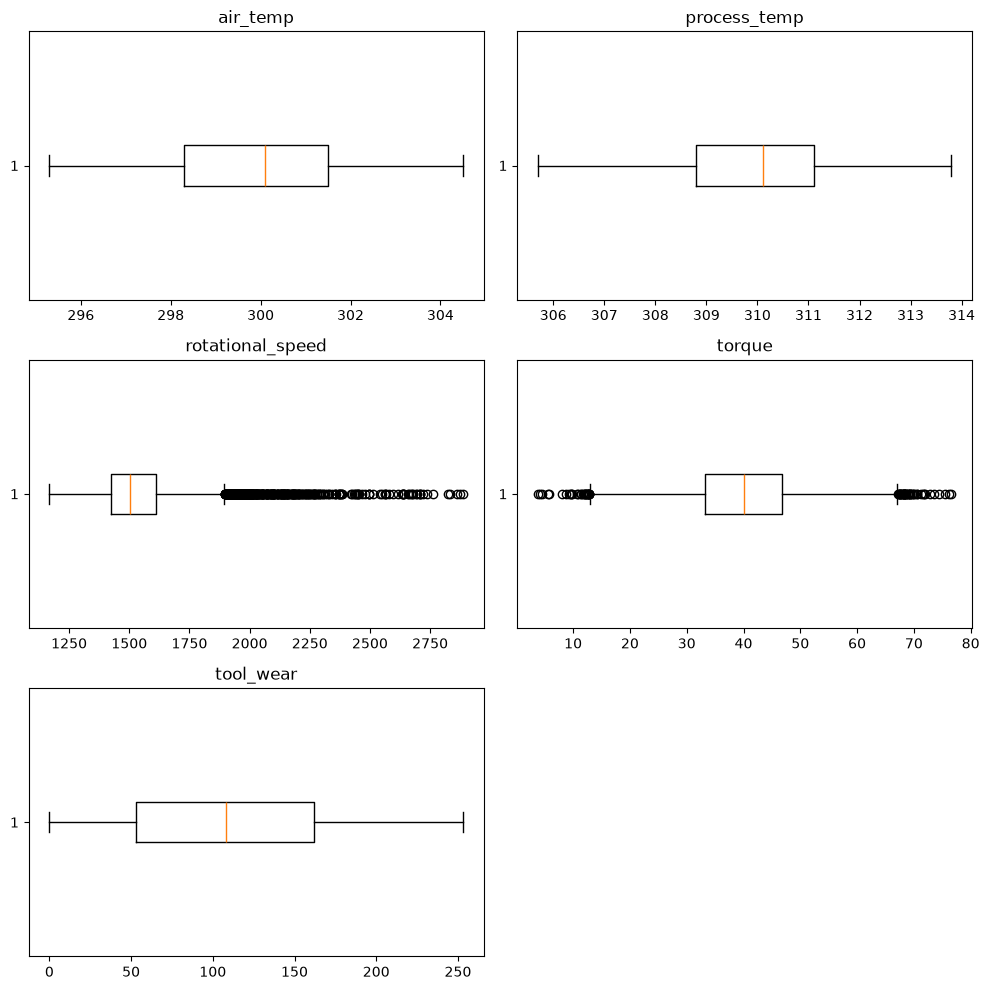

In [6]:
fig, axes = plt.subplots(3, 2, figsize=(10, 10))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    axes[i].boxplot(df_clean[col], orientation="horizontal")
    axes[i].set_title(col)

# Hide the empty 6th plot
axes[5].axis("off")

plt.tight_layout()
plt.show()

We also check the correlation between the numeric columns. This helps us pick two variables that give different information.

In [7]:
print(df_clean[numeric_cols].corr().round(2))

                  air_temp  process_temp  rotational_speed  torque  tool_wear
air_temp             1.000         0.880             0.020  -0.010      0.010
process_temp         0.880         1.000             0.020  -0.010      0.010
rotational_speed     0.020         0.020             1.000  -0.880      0.000
torque              -0.010        -0.010            -0.880   1.000     -0.000
tool_wear            0.010         0.010             0.000  -0.000      1.000


**What we see (this matches our earlier assignments):**

- The columns are on **very different scales**. Rotational speed is around 1,500 rpm, but torque is around 40 Nm. If we cluster without
  standardizing, speed would control the whole result just because its numbers are bigger.
- **Rotational speed has a lot of outliers on the high side** (up to 2,886 rpm). The skew row in the summary table confirms what we found in
  our first assignment: it is the only strongly skewed sensor (**skew ≈ 1.99**; all the others are close to 0).
- **Torque** has outliers on both sides but is balanced (mean ≈ median ≈ 40). In Workshop A the Shapiro-Wilk test showed torque
  is **bell-shaped** for all 10,000 runs (W = 0.9998, p = 0.38).
- **Tool wear** has no outliers and is spread fairly evenly from 0 to about 250 minutes.
- **Air and process temperature** move together (correlation ≈ 0.88), and they have a very small range (std of only 1.5–2 K).
- **Rotational speed and torque are strongly negatively correlated (≈ -0.88)** – when the machine spins faster, the torque is lower.

## 5. Choose the Two Clustering Variables (the 'centres')

### Variables chosen: `rotational_speed` and `torque`

**Why these two?**

- They are the two variables that best describe **how hard the machine is working**. Mechanical power is basically
  *torque × rotational speed*, so together they describe the machine's operating condition.
- Our earlier work pointed straight at them:
  - **Torque** was the strongest single warning sign (failed median 53.7 Nm vs 39.9 Nm, and the Workshop A t-test was highly significant).
  - **Rotational speed** – the slowest quarter of runs (Q1) had a **10.2%** failure rate, and the highest-torque quarter (Q4) had **9.9%**.
  - The torque vs. speed scatter plot from our first assignment showed failures grouped at the two ends of the band.
- Three of the failure types are linked to them: **power failure** (power too low or too high), **overstrain failure**
  (high torque) and **heat dissipation failure** (low speed means less cooling).
- We did not pick the two temperatures because they are very similar to each other and have a tiny range.
- We also tried **torque and tool wear** (tool wear Q4 also had a higher failure rate of 6.9%), but those two have no
  relationship (correlation ≈ 0), so the points form one big round "blob" with no natural splits. The check in Section 8
  shows that with k = 4 they explain only **69%** of the variation, compared with **83%** for speed + torque.

## 6. Standardize the Data

Set up the two standardization functions from class.

In [8]:
# Functions to Standardize Data
# First Standardization (Min-Max, puts everything between 0 and 1)
def sta01(x):
    return (x - x.min()) / (x.max() - x.min())

# Second Standardization (Z-score, mean of 0 and standard deviation of 1)
def stamn(x):
    return (x - x.mean()) / x.std()

### Compare the two methods on speed and torque

Before choosing, we apply **both** methods to our two variables and compare the result.

In [9]:
compare = pd.DataFrame({
    "speed min-max":  sta01(df_clean["rotational_speed"]),
    "torque min-max": sta01(df_clean["torque"]),
    "speed z-score":  stamn(df_clean["rotational_speed"]),
    "torque z-score": stamn(df_clean["torque"]),
})
print(compare.describe().round(2))

       speed min-max  torque min-max  speed z-score  torque z-score
count      10000.000       10000.000      10000.000       10000.000
mean           0.220           0.500         -0.000           0.000
std            0.100           0.140          1.000           1.000
min            0.000           0.000         -2.070          -3.630
25%            0.150           0.400         -0.650          -0.680
50%            0.190           0.500         -0.200           0.010
75%            0.260           0.590          0.410           0.680
max            1.000           1.000          7.510           3.670


### Standardization chosen: Z-score (`stamn`)

- We **must** standardize: rotational speed (≈1,500 rpm) and torque (≈40 Nm) are on very different scales, and k-means
  measures straight-line (Euclidean) distance, so without scaling speed would decide the clusters on its own.
- **The key point is weighting.** In k-means, each variable's influence on the distance is its *spread after scaling*.
  - With **z-score**, both variables end up with a standard deviation of exactly **1**, so speed and torque count **equally**.
  - With **min-max**, each variable is divided by its *range*, which is set by the single most extreme reading.
    Speed has a long right tail (max 2,886 rpm is about 7.5 standard deviations above the mean), so its range is huge.
    The table above shows the result: speed's standard deviation shrinks to about **0.10** while torque's is about **0.14**,
    so min-max would quietly give speed **less** weight than torque. It also squashes 75% of the speed readings into the
    bottom quarter of the 0–1 scale (75th percentile ≈ 0.26).
- The z-score is not completely immune to outliers (the mean and standard deviation move a little too), but it does not
  depend on one extreme value the way min-max does.
- Torque is bell-shaped (Workshop A), and a z-score is easy to explain: 0 = average, ±1 = one standard deviation above/below.
- In Section 9 we also re-run the final clustering with min-max to check that our conclusions do **not** depend on this choice.

In [10]:
df_clean["rotational_speed_std"] = stamn(df_clean["rotational_speed"])
df_clean["torque_std"] = stamn(df_clean["torque"])

print("Standardized Variables (first rows)")
print(df_clean[["rotational_speed", "torque", "rotational_speed_std", "torque_std"]].head())

# Quick check: mean should be about 0 and std should be 1
print("\nCheck mean and standard deviation")
print(df_clean[["rotational_speed_std", "torque_std"]].describe().round(2))

Standardized Variables (first rows)
   rotational_speed  torque  rotational_speed_std  torque_std
0              1551  42.800                 0.068       0.282
1              1408  46.300                -0.729       0.633
2              1498  49.400                -0.227       0.944
3              1433  39.500                -0.590      -0.049
4              1408  40.000                -0.729       0.001

Check mean and standard deviation
       rotational_speed_std  torque_std
count             10000.000   10000.000
mean                 -0.000       0.000
std                   1.000       1.000
min                  -2.070      -3.630
25%                  -0.650      -0.680
50%                  -0.200       0.010
75%                   0.410       0.680
max                   7.510       3.670


## 7. Generate Clusters (Looping through possible ks)

Same loop as the class demo: we try k = 1 to 7 and save the Total, Between and Within Sum of Squares for each.

KMeans numbers its clusters in an arbitrary order. To make the numbering the **same on every computer**, we renumber
the clusters from **slowest (1) to fastest (k)** average rotational speed. Each cluster number also keeps the same
colour in every plot below.

In [11]:
# Same k-means settings as the class demo, used for EVERY k-means run in this notebook
KMEANS_SETTINGS = {"max_iter": 10, "n_init": 10, "random_state": 123}

# One fixed colour per cluster number (1 = slowest ... 5 = fastest), used in every plot
CLUSTER_COLOURS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]

# KMeans numbers clusters in a random order. These helpers renumber them from slowest to fastest.
# (Column 0 of the clustering data is always rotational speed.)
def speed_order(km):
    """Positions of the centres sorted from slowest to fastest rotational speed."""
    return np.argsort(km.cluster_centers_[:, 0])

def ordered_labels(km):
    """Cluster number (1..k) for every run, numbered from slowest to fastest centre."""
    rank = np.empty(km.n_clusters, dtype=int)
    rank[speed_order(km)] = np.arange(1, km.n_clusters + 1)
    return rank[km.labels_]

def ordered_centres(km):
    """Cluster centres in the same slowest-to-fastest order."""
    return km.cluster_centers_[speed_order(km)]

In [12]:
maxk = 7
nk = range(1, maxk + 1)
wss = np.zeros(maxk)
ratio = np.zeros(maxk)

# Variables used for clustering
X = df_clean[["rotational_speed_std", "torque_std"]]

# Place to store cluster models
cluster_models = {}
loop_summary = []

# Total SS is the same for every k
total_ss = ((X - X.mean())**2).sum().sum()

# Generate Clusters
for k in nk:

    km = KMeans(n_clusters=k, **KMEANS_SETTINGS)
    km.fit(X)
    cluster_models[k] = km

    within_ss = km.inertia_
    between_ss = total_ss - within_ss

    # Store WSS for elbow chart and the Between/Total ratio
    wss[k - 1] = within_ss
    ratio[k - 1] = between_ss / total_ss

    loop_summary.append({
        "k": k,
        "Sizes (slowest -> fastest)": np.bincount(ordered_labels(km))[1:].tolist(),
        "Iterations": km.n_iter_,
        "Total SS": round(total_ss),
        "Between SS": round(between_ss),
        "Within SS": round(within_ss),
    })

print(pd.DataFrame(loop_summary).to_string(index=False))

 k              Sizes (slowest -> fastest)  Iterations  Total SS  Between SS  Within SS
 1                                 [10000]           2     19998           0      19998
 2                            [6490, 3510]           6     19998       11310       8688
 3                      [4335, 4544, 1121]           9     19998       14927       5071
 4                 [2608, 4161, 2639, 592]           9     19998       16615       3383
 5           [2001, 3692, 2959, 1159, 189]           7     19998       17502       2496
 6      [1292, 2844, 2899, 2042, 775, 148]          10     19998       18111       1887
 7 [996, 2265, 2555, 2135, 1334, 586, 129]           7     19998       18434       1564


## 8. Compare Different Values of 'k' to Find Optimal

### Elbow Chart

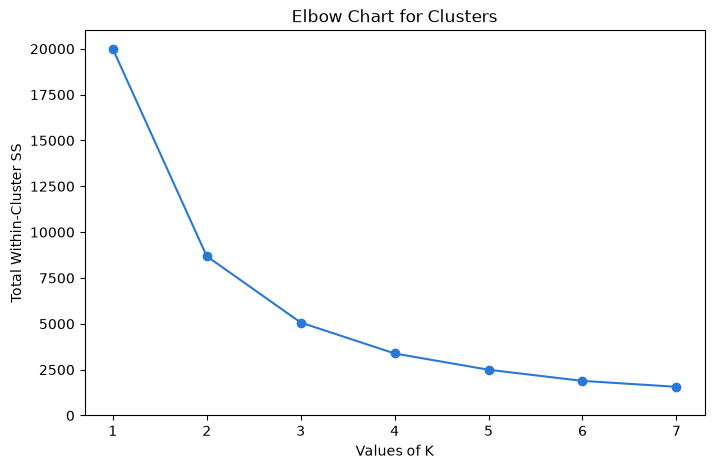

In [13]:
plt.figure(figsize=(8, 5))
plt.plot(list(nk), wss, marker="o", color=CLUSTER_COLOURS[0])

plt.title("Elbow Chart for Clusters")
plt.xlabel("Values of K")
plt.ylabel("Total Within-Cluster SS")
plt.ylim(0, max(wss) * 1.05)

plt.show()

### Between SS / Total SS

Another check is the percentage of the total variation that is explained by the clusters (Between SS ÷ Total SS).
Higher is better, but we also want to see where adding more clusters stops helping much.

In [14]:
ss_table = pd.DataFrame({
    "k": list(nk),
    "Within SS": wss.round(0),
    "Between/Total (%)": (ratio * 100).round(1)
})

# How much the Within SS drops each time we add one more cluster
ss_table["Drop in Within SS"] = (-ss_table["Within SS"].diff()).round(0)

print(ss_table)

   k  Within SS  Between/Total (%)  Drop in Within SS
0  1  19998.000              0.000                NaN
1  2   8688.000             56.600          11310.000
2  3   5071.000             74.600           3617.000
3  4   3383.000             83.100           1688.000
4  5   2496.000             87.500            887.000
5  6   1887.000             90.600            609.000
6  7   1564.000             92.200            323.000


### Check: would torque + tool wear have been a better pair?

In Section 5 we said we also tried **torque + tool wear**. Here is the evidence: we run the same loop on that pair
(also z-score standardized) and put both elbow curves on one chart. Both pairs start from the same Total SS (19,998),
so the curves can be compared directly.

 k  Speed + Torque: Between/Total (%)  Torque + Tool wear: Between/Total (%)
 1                              0.000                                  0.000
 2                             56.600                                 37.400
 3                             74.600                                 57.300
 4                             83.100                                 69.300
 5                             87.500                                 74.100
 6                             90.600                                 78.300
 7                             92.200                                 81.600


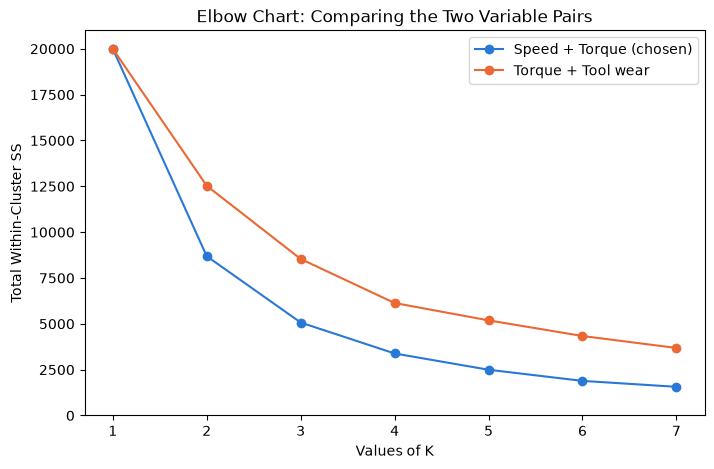

In [15]:
X_alt = pd.DataFrame({
    "torque_std":    stamn(df_clean["torque"]),
    "tool_wear_std": stamn(df_clean["tool_wear"]),
})
total_alt = ((X_alt - X_alt.mean())**2).sum().sum()

wss_alt = np.zeros(maxk)
for k in nk:
    wss_alt[k - 1] = KMeans(n_clusters=k, **KMEANS_SETTINGS).fit(X_alt).inertia_
ratio_alt = (total_alt - wss_alt) / total_alt

pair_compare = pd.DataFrame({
    "k": list(nk),
    "Speed + Torque: Between/Total (%)": (ratio * 100).round(1),
    "Torque + Tool wear: Between/Total (%)": (ratio_alt * 100).round(1).clip(min=0),  # clip hides a -0.0 at k = 1
})
print(pair_compare.to_string(index=False))

plt.figure(figsize=(8, 5))
plt.plot(list(nk), wss, marker="o", color=CLUSTER_COLOURS[0], label="Speed + Torque (chosen)")
plt.plot(list(nk), wss_alt, marker="o", color=CLUSTER_COLOURS[1], label="Torque + Tool wear")
plt.title("Elbow Chart: Comparing the Two Variable Pairs")
plt.xlabel("Values of K")
plt.ylabel("Total Within-Cluster SS")
plt.ylim(0, max(wss) * 1.05)
plt.legend()
plt.show()

### Compare possible solutions (scatter plots)

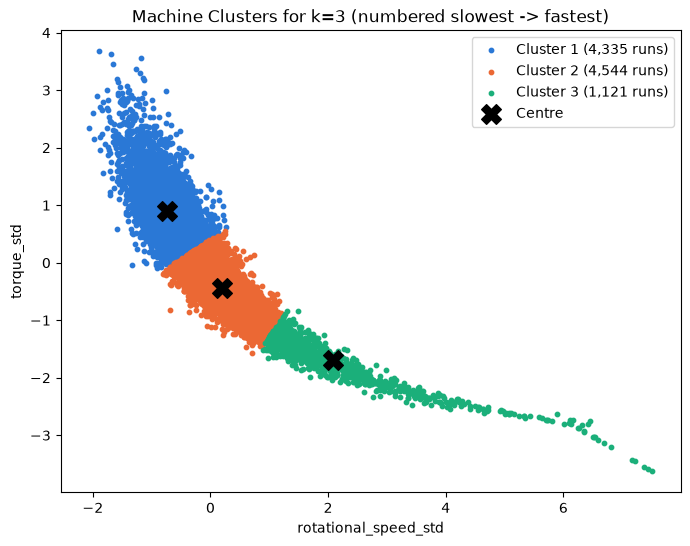

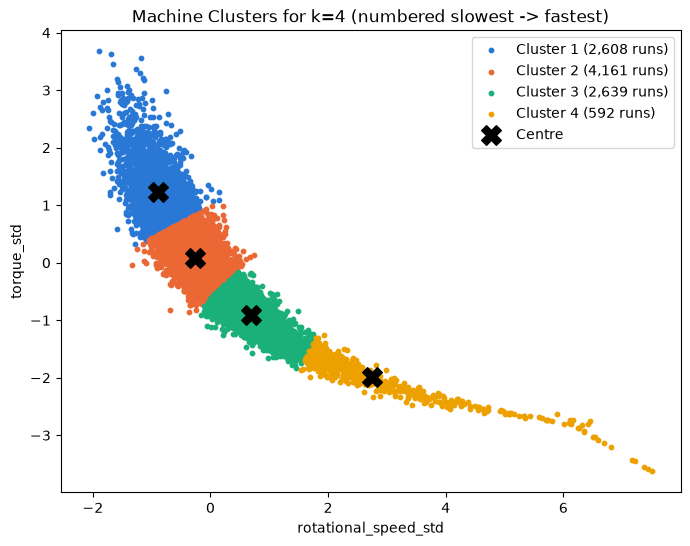

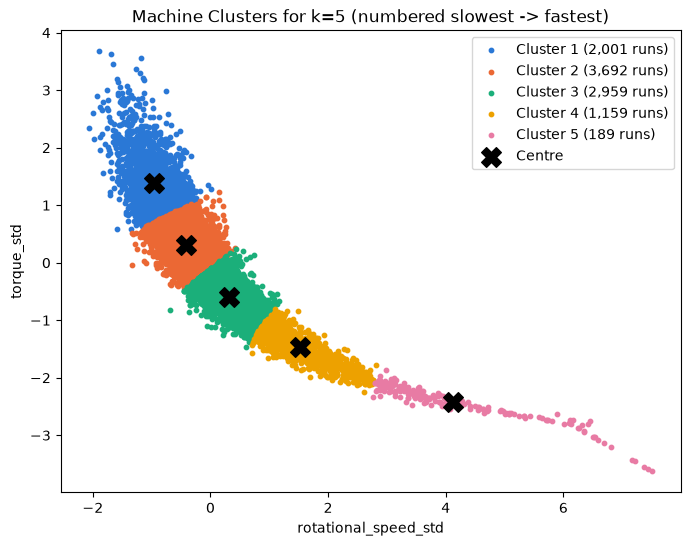

In [16]:
# The k values around the elbow that we compare in detail
candidate_ks = [3, 4, 5]

for k in candidate_ks:

    labels = ordered_labels(cluster_models[k])

    plt.figure(figsize=(8, 6))

    for c in range(1, k + 1):
        members = labels == c
        plt.scatter(
            df_clean.loc[members, "rotational_speed_std"],
            df_clean.loc[members, "torque_std"],
            color=CLUSTER_COLOURS[c - 1],
            s=10,
            label=f"Cluster {c} ({members.sum():,} runs)"
        )

    # Show the centres as black X's
    centres = ordered_centres(cluster_models[k])
    plt.scatter(centres[:, 0], centres[:, 1], c="black", marker="X", s=200, label="Centre")

    plt.title(f"Machine Clusters for k={k} (numbered slowest -> fastest)")
    plt.xlabel("rotational_speed_std")
    plt.ylabel("torque_std")
    plt.legend()

    plt.show()

### Failure rate inside each cluster for k = 3, 4 and 5

The elbow chart and the ratio only tell us how *compact* the clusters are. Our goal (Section 3) is to find operating
zones with different **risk**, so we also check how well each k separates failures. KMeans still never sees the failure
column; we only use it *after* clustering to judge which k is most useful.

In [17]:
k_compare = []
for k in candidate_ks:
    labels = ordered_labels(cluster_models[k])
    by_cluster = df_clean.groupby(labels)["machine_failure"]
    k_compare.append({
        "k": k,
        "Runs per cluster (slowest -> fastest)": by_cluster.size().tolist(),
        "Failure % per cluster": (by_cluster.mean() * 100).round(1).tolist(),
    })

print(pd.DataFrame(k_compare).to_string(index=False))

 k Runs per cluster (slowest -> fastest)       Failure % per cluster
 3                    [4335, 4544, 1121]             [6.4, 0.6, 3.4]
 4               [2608, 4161, 2639, 592]       [10.0, 0.6, 0.5, 6.2]
 5         [2001, 3692, 2959, 1159, 189] [11.8, 1.2, 0.6, 0.5, 17.5]


### Our Choice: k = 4

**Elbow chart:** The sharpest bend is at k = 2–3 (the Within SS drops by 11,310 and then by 3,617). From k = 4 onwards
each extra cluster removes less than 900 (887 at k = 5, 609 at k = 6), so the curve is flat after 4. The elbow on its own
points to **k = 3 or 4**, so we use the other checks to decide.

**Between/Total ratio:** k = 3 explains 74.6% of the variation, k = 4 explains **83.1%** (+8.5 points), and k = 5 only
adds another 4.4 points (87.5%).

**Scatter plots:** Speed and torque are strongly correlated (-0.88), so the data is one long diagonal band. K-means
cuts this band into **operating zones**; it is not finding separate "islands" of points.
- **k = 3:** the slowest cluster (4,335 runs) mixes heavy-load runs with normal ones, so its failure rate is diluted to
  6.4%. The fastest cluster (1,121 runs, 3.4%) mixes the risky extreme tail with safe moderate-fast runs.
- **k = 4:** a clean split into two **risky end zones** (10.0% and 6.2% failure) and two **safe middle zones** (0.6% and
  0.5%). Each cluster is an easy-to-name operating condition.
- **k = 5:** the extra cluster does **not** split the middle. It splits the **fast end** into a safe group (1,159 runs,
  0.5%) and a small extreme tail (**189 runs, 17.5% failure**, the riskiest group in any solution). It also sharpens
  the slow end a little (11.8%).

**Decision:** We choose **k = 4**. It is at the end of the elbow, explains 83% of the variation, and it is the smallest k
that separates **both** high-risk zones from the safe middle. k = 5 is a reasonable alternative because it isolates the
extreme very-high-speed tail. However, that group is under 2% of the runs, the gain in explained variation is small, and
the overall story stays the same: the risk is at both ends of the band. We mention the extreme tail as a sub-zone in our
insights instead of making it a separate cluster.

## 9. Summarize Details of Final Clustering Scheme

Now we put the k = 4 cluster numbers onto the data and summarize **all** the variables (not only the two used to make the
clusters), including the failure columns.

*The clusters are numbered from slowest (1) to fastest (4) average speed, so the numbers and names below are the same
on every computer.*

In [18]:
df_clean["cluster"] = ordered_labels(cluster_models[4])

# Summarize Clusters (averages)
SummClusters = (
    df_clean.groupby("cluster")[["rotational_speed", "torque", "tool_wear", "air_temp", "process_temp"]]
    .mean()
    .round(1)
)

# Number of readings in each cluster
SummClusters["Count"] = df_clean.groupby("cluster").size()

print("Cluster Summary (averages)")
print(SummClusters)

Cluster Summary (averages)
         rotational_speed  torque  tool_wear  air_temp  process_temp  Count
cluster                                                                    
1                1377.700  52.200    107.500   300.000       310.000   2608
2                1491.000  40.900    107.700   299.900       310.000   4161
3                1662.500  30.900    109.100   300.000       310.000   2639
4                2032.400  20.200    106.500   300.200       310.100    592


Next, the failure rate in each cluster (as a %). Remember that KMeans never saw these columns.

In [19]:
FailClusters = (df_clean.groupby("cluster")[failure_cols].mean() * 100).round(2)

# Shorter column names so the table fits on the screen
FailClusters.columns = ["All failures", "Tool wear", "Heat dissipation", "Power", "Overstrain", "Random"]

print("Failure Rate by Cluster (%)")
print(FailClusters)

print(f"\nOverall failure rate for the whole dataset: {df_clean['machine_failure'].mean() * 100:.2f}%")

Failure Rate by Cluster (%)
         All failures  Tool wear  Heat dissipation  Power  Overstrain  Random
cluster                                                                      
1              10.010      0.420             4.220  2.450       3.680   0.350
2               0.650      0.430             0.120  0.000       0.050   0.120
3               0.530      0.420             0.000  0.000       0.000   0.190
4               6.250      1.010             0.000  5.240       0.000   0.000

Overall failure rate for the whole dataset: 3.39%


Failure rates are percentages, so we also count **how many** of the 339 failures land in each cluster.

In [20]:
FailCount = df_clean.groupby("cluster")["machine_failure"].sum().to_frame("Failures")
FailCount["% of all failures"] = (FailCount["Failures"] / FailCount["Failures"].sum() * 100).round(1)
FailCount["% of all runs"] = (df_clean.groupby("cluster").size() / len(df_clean) * 100).round(1)

print(FailCount)

         Failures  % of all failures  % of all runs
cluster                                            
1             261             77.000         26.100
2              27              8.000         41.600
3              14              4.100         26.400
4              37             10.900          5.900


### Check: does the standardization method change the result?

We re-run k = 4 using **min-max** (`sta01`) instead of the z-score and compare the clusters (sorted from slowest to fastest).

In [21]:
X_minmax = pd.DataFrame({
    "speed":  sta01(df_clean["rotational_speed"]),
    "torque": sta01(df_clean["torque"]),
})
km_minmax = KMeans(n_clusters=4, **KMEANS_SETTINGS).fit(X_minmax)

# Same slowest -> fastest numbering as our z-score clusters, so the rows line up with the tables above
MinMaxCheck = (
    df_clean.groupby(ordered_labels(km_minmax))
    .agg(Runs=("machine_failure", "size"),
         Avg_speed=("rotational_speed", "mean"),
         Avg_torque=("torque", "mean"),
         Failure_pct=("machine_failure", "mean"))
)
MinMaxCheck.index.name = "cluster"
MinMaxCheck["Failure_pct"] = MinMaxCheck["Failure_pct"] * 100
print(MinMaxCheck.round(1))

         Runs  Avg_speed  Avg_torque  Failure_pct
cluster                                          
1        2451   1377.500      52.600       10.300
2        4082   1483.600      41.400        0.800
3        2807   1648.900      31.400        0.500
4         660   2010.400      20.600        5.600


Min-max gives the **same four operating zones** in the same order (slow & heavy → fast & light) with very similar
failure rates. The cluster sizes shift a little because min-max gives speed less weight, but the conclusions in
Section 10 are the same with either method.

And how the product quality `type` is spread across the clusters (% of each cluster).

In [22]:
TypeClusters = (pd.crosstab(df_clean["cluster"], df_clean["type"], normalize="index") * 100).round(1)

print("\nProduct Type by Cluster (%)")
print(TypeClusters)


Product Type by Cluster (%)
type         H      L      M
cluster                     
1        9.700 60.500 29.800
2       10.300 59.800 29.900
3       10.100 59.900 30.000
4        9.300 59.800 30.900


### Give the Clusters Descriptive Names

In [23]:
cluster_names = {
    1: "Slow & Heavy Load",
    2: "Normal Operation",
    3: "Moderate-Fast, Light Load",
    4: "Fast & Light Load"
}

df_clean["cluster_name"] = df_clean["cluster"].map(cluster_names)

Final = SummClusters.copy()
Final["Failure %"] = FailClusters["All failures"]
Final.index = Final.index.map(cluster_names)

print(Final)

                           rotational_speed  torque  tool_wear  air_temp  \
cluster                                                                    
Slow & Heavy Load                  1377.700  52.200    107.500   300.000   
Normal Operation                   1491.000  40.900    107.700   299.900   
Moderate-Fast, Light Load          1662.500  30.900    109.100   300.000   
Fast & Light Load                  2032.400  20.200    106.500   300.200   

                           process_temp  Count  Failure %  
cluster                                                    
Slow & Heavy Load               310.000   2608     10.010  
Normal Operation                310.000   4161      0.650  
Moderate-Fast, Light Load       310.000   2639      0.530  
Fast & Light Load               310.100    592      6.250  


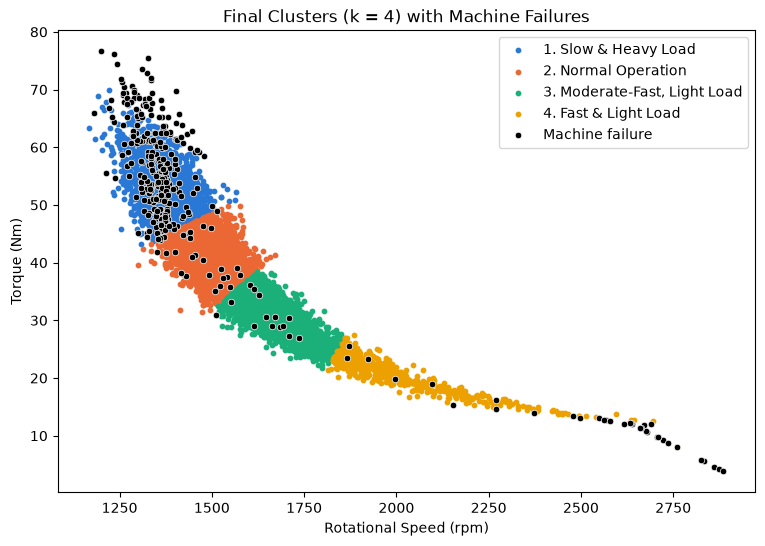

In [24]:
# Final scatter plot using the real (not standardized) values and the cluster names
plt.figure(figsize=(9, 6))

for c, name in cluster_names.items():
    group = df_clean[df_clean["cluster"] == c]
    plt.scatter(group["rotational_speed"], group["torque"], s=10,
                color=CLUSTER_COLOURS[c - 1], label=f"{c}. {name}")

# Show failures as black dots on top
failed = df_clean[df_clean["machine_failure"] == 1]
plt.scatter(failed["rotational_speed"], failed["torque"], c="black", s=22,
            edgecolors="white", linewidths=0.5, label="Machine failure")

plt.title("Final Clusters (k = 4) with Machine Failures")
plt.xlabel("Rotational Speed (rpm)")
plt.ylabel("Torque (Nm)")
plt.legend()
plt.show()

### A closer look at the failures inside the risky clusters

In the final plot there is a **vertical stripe** of failures at about 1,350–1,380 rpm inside *Slow & Heavy Load*.
We check which failure type that is, and whether the power failures in the two end zones are the same kind.
Power is torque × angular speed: `torque × rpm × 2π / 60` (in watts).

In [25]:
hdf = df_clean[df_clean["heat_dissipation_failure"] == 1]
df_clean["temp_gap"] = df_clean["process_temp"] - df_clean["air_temp"]

print(f"Heat dissipation failures: {len(hdf)}")
print(f"  Rotational speed range: {hdf['rotational_speed'].min()} - {hdf['rotational_speed'].max()} rpm")
print(f"  Largest air-process temperature gap: {df_clean.loc[hdf.index, 'temp_gap'].max():.1f} K "
      f"(all runs: {df_clean['temp_gap'].min():.1f} - {df_clean['temp_gap'].max():.1f} K)")
print(f"  Share in cluster 1 (Slow & Heavy Load): {(hdf['cluster'] == 1).mean() * 100:.1f}%")

# Mechanical power in watts = torque (Nm) x angular speed (rad/s)
df_clean["power_w"] = df_clean["torque"] * df_clean["rotational_speed"] * 2 * np.pi / 60
pwf = df_clean[df_clean["power_failure"] == 1]

print("\nPower failures by cluster (power in watts)")
print(pwf.groupby("cluster_name")["power_w"].agg(["count", "min", "max"]).round(0))

Heat dissipation failures: 115
  Rotational speed range: 1212 - 1379 rpm
  Largest air-process temperature gap: 8.6 K (all runs: 7.6 - 12.1 K)
  Share in cluster 1 (Slow & Heavy Load): 95.7%

Power failures by cluster (power in watts)
                   count      min       max
cluster_name                               
Fast & Light Load     31 1148.000  3477.000
Slow & Heavy Load     64 9004.000 10470.000


## 10. Insights from the Clusters

| Cluster | Name | Avg Speed (rpm) | Avg Torque (Nm) | Runs | Failure rate |
|---|---|---|---|---|---|
| 1 | **Slow & Heavy Load** | ~1,378 | ~52 | 2,608 | **10.0%** |
| 2 | **Normal Operation** | ~1,491 | ~41 | 4,161 | 0.7% |
| 3 | **Moderate-Fast, Light Load** | ~1,663 | ~31 | 2,639 | 0.5% |
| 4 | **Fast & Light Load** | ~2,032 | ~20 | 592 | **6.3%** |

(The overall failure rate for the whole dataset is 3.4%.)

**What the clusters tell us:**

1. **Most failures happen in the two "extreme" clusters.** *Slow & Heavy Load* and *Fast & Light Load* together
   hold only about 32% of the runs, but **298 of the 339 failures (about 88%)**. The two "middle" clusters
   almost never fail (under 1%). The machine is safest when it runs in the middle of the speed/torque range.

2. **This confirms what we saw in our earlier assignments, but now the groups were found automatically.**
   In the first assignment the scatter plot showed failures in the top-left and bottom-right corners, and in Workshop A the torque
   of failed runs looked like two separate groups. KMeans never saw the `machine_failure` column, yet it still drew boundaries
   that separate the high-risk zones from the safe ones.

3. **Each extreme cluster fails in a different way.**
   - *Slow & Heavy Load* has the most **heat dissipation** and **overstrain** failures. **95.7% of all heat dissipation
     failures** are in this cluster, and every one of them happened below **1,380 rpm** with an air-to-process temperature
     gap of **8.6 K or less**. That is the vertical stripe in the final plot: at low speed the tool is not cooled enough.
     This also explains the Workshop A t-test result (failed machines have higher average torque).
   - *Fast & Light Load* has almost only **power failures**. It is the smallest cluster (592 runs) but has the highest
     power-failure rate (about 5%). These are the "low-torque" failures we saw in the Workshop A Q-Q plot.
   - The power failures in the two end zones are **opposite problems**: in *Fast & Light Load* the power is too **low**
     (all below 3,500 W), and in *Slow & Heavy Load* it is too **high** (all above 9,000 W). These limits match the
     failure rules published with the UCI dataset.

4. **The extreme tail is the riskiest place of all.** The k = 5 solution showed that the 189 runs at the very fast end of the
   band (centre at about 2,280 rpm and 13 Nm) fail **17.5%** of the time (33 failures). Within *Fast & Light Load*, the further out on the tail a machine runs, the
   higher the risk.

5. **Tool wear, temperature and product type look the same in every cluster.** Average tool wear is about 107 minutes and the
   L/M/H split is about 60/30/10 in all four clusters. So the clusters are about *how* the machine is being run
   (speed and torque), not *which* product or *how old* the tool is.
   - Tool wear failures and random failures are spread out evenly, so these clusters can't predict those two types.
     Our earlier finding that worn tools (tool wear Q4) fail more often (6.9%) is a **separate** risk that speed and torque don't capture.
   - Our first assignment found that L-grade products fail more often (3.9% vs 2.1% for H). Since every cluster has the same
     product mix, that difference is **not** caused by L products being run at riskier speed/torque settings. A likely reason
     is that, according to the UCI dataset description, the **overstrain limit is lower for L products**
     (tool wear × torque above 11,000 minNm for L, 12,000 for M, 13,000 for H).

6. **Practical use:** A maintenance team could use these two sensors as an early warning. If a machine moves into the
   *Slow & Heavy Load* or *Fast & Light Load* zone, it should be checked or adjusted, because that is where the risk of failure
   jumps from under 1% to between 6% and 10% (and to about 17% at the very fast end). Tool wear should still be watched separately.

7. **Limitations:** Because speed and torque are so strongly correlated, the clusters are slices of one continuous band
   (operating zones), not completely separate groups. Runs near a boundary could easily belong to either neighbouring
   cluster. We kept `max_iter = 10` from the class demo; the iteration column in Section 7 shows the runs converged
   (only k = 6 reached the limit, and it is not part of our final scheme).

8. **Next step for our term project:** speed and torque together are very useful for predicting failure, and the power
   check above shows that **power = torque × speed** separates the power failures cleanly. It is a strong new feature
   to try in our later models.